# TP: Machine Learning

## TP1: Linear Regression (4h)  

Linear regression is a family of machine learning algorithms aiming at adjusting a linear model to an ensemble of data. The applications range from signal reconstruction to empirical description.

The given dataset was produced by the World Health Organization. It pooled the evolution of 20 features for 15 years and among numerous countries. One of the goals of this TP1 is to manipulate this dataset and try to predict the evolution of Life Expectancy through different variables.

**Objectives:**
- Use and setup an iPython environment
- Manipulate and visualize data
- Implement a simple linear regression
- Apply the aforementioned linear regression
- Compute a $R^2$ on the generated results
- Apply Ridge and Lasso regressions


To code this TP, you can use your own iPython environment, or chose to use the ENSEA's jupyter server available on https://io.ensea.fr

This TP has different **checkpoints**. Please call your teacher at the end of each checkpoint to validate your work. Any non validated work won't be taken into account in the notation


## STEP 1: Use and setup an iPython environment

iPython and Notebook environments are useful tools to quickly prototype and test machine learning solutions. However, they have limitations especially in RAM and disk access.

**TO DO 1.1**

Execute the following cells

In [2]:
a = 3
b = 4
c = a + b

In [3]:
c = c

In [4]:
print(c)

7


In [5]:
c

7

**QUESTION 1**

What is triggering the output display?

**TO DO 1.2**

Execute the following cells

In [6]:
import shutil
import pkgutil

def show_acceptable_modules():
    line = '-' * 100
    print('{}\n{:^30}|{:^20}\n{}'.format(line, 'Module', 'Location', line))
    for entry in pkgutil.iter_modules():
        print('{:30}| {}'.format(entry[1], entry[0].path))

In [7]:
show_acceptable_modules()

----------------------------------------------------------------------------------------------------
            Module            |      Location      
----------------------------------------------------------------------------------------------------
_asyncio                      | c:\Users\fatim\AppData\Local\Programs\Python\Python310\DLLs
_bz2                          | c:\Users\fatim\AppData\Local\Programs\Python\Python310\DLLs
_ctypes                       | c:\Users\fatim\AppData\Local\Programs\Python\Python310\DLLs
_ctypes_test                  | c:\Users\fatim\AppData\Local\Programs\Python\Python310\DLLs
_decimal                      | c:\Users\fatim\AppData\Local\Programs\Python\Python310\DLLs
_elementtree                  | c:\Users\fatim\AppData\Local\Programs\Python\Python310\DLLs
_hashlib                      | c:\Users\fatim\AppData\Local\Programs\Python\Python310\DLLs
_lzma                         | c:\Users\fatim\AppData\Local\Programs\Python\Python310\DLLs
_msi      

**QUESTION 2**

What is displayed on the last output?

Which is the used Python version?

For this TP1, you will need:
- pandas
- matplotlib
- numpy
- sklearn

Are these packages installed in this environment?

**TO DO 1.3**

Execute the following cell

In [8]:
pandas.__version__

NameError: name 'pandas' is not defined

**QUESTION 3**

How would you solve this error? by importing pandas first

## STEP 2: Data manipulation and visualization


**TO DO 2.1**

Execute the following cell

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/Life_Expectancy_Data.csv")
df = df.dropna()
df.info()

<class 'pandas.DataFrame'>
Index: 1649 entries, 0 to 2937
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          1649 non-null   str    
 1   Year                             1649 non-null   int64  
 2   Status                           1649 non-null   str    
 3   Life_expectancy                  1649 non-null   float64
 4   Adult_mortality                  1649 non-null   float64
 5   Infant_deaths                    1649 non-null   int64  
 6   Alcohol                          1649 non-null   float64
 7   Percentage_expenditure           1649 non-null   float64
 8   Hepatitis_B                      1649 non-null   float64
 9   Measles                          1649 non-null   int64  
 10  BMI                              1649 non-null   float64
 11  Under-five_deaths                1649 non-null   int64  
 12  Polio                            164

**QUESTION 4**

Can you explain the different elements printed on the last output?

How mnay column belong to each of these types

In [12]:
df1 = df[(df.Country == "France") & (df.Year > 2010)]
print("df1: ", df1)
df2 = df[(df.Country == "France")].Year
print("df2: ", df2)

df1:      Country  Year      Status  Life_expectancy  Adult_mortality  \
931  France  2014  Developing             82.2             79.0   
932  France  2013  Developing             82.0             81.0   
933  France  2012  Developing             81.5             83.0   
934  France  2011  Developing             81.7             83.0   

     Infant_deaths  Alcohol  Percentage_expenditure  Hepatitis_B  Measles  \
931              3     11.5             6739.677606         83.0      267   
932              3     11.1             6646.953935         74.0      272   
933              3     11.5              751.379355         78.0        0   
934              3     11.8              683.919057         74.0    14949   

     ...  Polio  Total_expenditure  Diphtheria  HIV_AIDS          GDP  \
931  ...   98.0              11.54        98.0       0.1  42955.24287   
932  ...   99.0              11.56        99.0       0.1  42554.12250   
933  ...   99.0              11.44        99.0       

**QUESTION 5**

How do you interpret the new Data Frame df1 compared to df? What represents df2 compared to df1?

df1 shows the information containing france as a country and above year 2010 , whereas the other shows the year info that are in the france category

**TO CODE 2.2**

What is the range of life expectancy of Belgium between 2004 and 2008?

In [13]:
df3 = df[(df.Country == 'Belgium') & (df.Year>=2004)& (df.Year<=2008)]
print("df3: ",df3)
lifeRange_max= df3[("Life_expectancy")].max()
lifeRange_min = df3[("Life_expectancy")].min()
print("life range is:",lifeRange_max , lifeRange_min) 

df3:       Country  Year     Status  Life_expectancy  Adult_mortality  \
247  Belgium  2008  Developed             79.5             87.0   
248  Belgium  2007  Developed             79.5             86.0   
249  Belgium  2006  Developed             79.4             85.0   
250  Belgium  2005  Developed             78.9             89.0   
251  Belgium  2004  Developed             78.8             91.0   

     Infant_deaths  Alcohol  Percentage_expenditure  Hepatitis_B  Measles  \
247              0    10.47             7191.051507         98.0       98   
248              0    10.25              640.356092         94.0       64   
249              0    10.98             5579.199083         94.0       15   
250              0    12.27             5068.214488         77.0       26   
251              1    12.05             5160.508378         64.0       61   

     ...  Polio  Total_expenditure  Diphtheria  HIV_AIDS          GDP  \
247  ...   99.0               9.60        99.0       0.

**TO DO 2.3**

Compute the correlation among all features

In [14]:
print(df.corr(numeric_only=True))

                                     Year  Life_expectancy  Adult_mortality  \
Year                             1.000000         0.050771        -0.037092   
Life_expectancy                  0.050771         1.000000        -0.702523   
Adult_mortality                 -0.037092        -0.702523         1.000000   
Infant_deaths                    0.008029        -0.169074         0.042450   
Alcohol                         -0.113365         0.402718        -0.175535   
Percentage_expenditure           0.069553         0.409631        -0.237610   
Hepatitis_B                      0.114897         0.199935        -0.105225   
Measles                         -0.053822        -0.068881        -0.003967   
BMI                              0.005739         0.542042        -0.351542   
Under-five_deaths                0.010479        -0.192265         0.060365   
Polio                           -0.016699         0.327294        -0.199853   
Total_expenditure                0.059493         0.

**QUESTION 6**

Which seems the most and the least promising values to use as a predictor for life expectancy?

Schooling (highest correlation coefficient) is most promising, Least promising is BMI (closest norm value to 0)

The function scatter of matplotlib allows to plot two values against each other. Here is the documentation about this function:

```
matplotlib.pyplot.scatter(x, y, s=None, c=None, marker=None, cmap=None, norm=None, vmin=None, vmax=None, alpha=None, linewidths=None, *, edgecolors=None, plotnonfinite=False, data=None, **kwargs)
```
Parameters:

**x, y** float or array-like, shape (n, )

The data positions.

**s** float or array-like, shape (n, ), optional

The marker size in points**2. Default is rcParams['lines.markersize'] ** 2.

**c** array-like or list of colors or color, optional

The marker colors. Possible values:

- A scalar or sequence of n numbers to be mapped to colors using cmap and norm.

- A 2D array in which the rows are RGB or RGBA.

- A sequence of colors of length n.

- A single color format string.

**marker** MarkerStyle, default: rcParams (default: 'o')

The marker style. marker can be either an instance of the class or the text shorthand for a particular marker. See matplotlib.markers for more information about marker styles.

**cmapstr** or Colormap, default: rcParams(default: 'viridis')

A Colormap instance or registered colormap name. cmap is only used if c is an array of floats.

**norm** Normalize, default: None

If c is an array of floats, norm is used to scale the color data, c, in the range 0 to 1, in order to map into the colormap cmap. If None, use the default colors.Normalize.

**vmin, vmax** float, default: None

vmin and vmax are used in conjunction with the default norm to map the color array c to the colormap cmap. If None, the respective min and max of the color array is used. It is deprecated to use vmin/vmax when norm is given.

**alpha** float, default: None

The alpha blending value, between 0 (transparent) and 1 (opaque).

**linewidths** float or array-like, default: rcParams (default: 1.5)

The linewidth of the marker edges. Note: The default edgecolors is 'face'. You may want to change this as well.

**edgecolors** {'face', 'none', None} or color or sequence of color, default: rcParams["scatter.edgecolors"] (default: 'face')

The edge color of the marker. Possible values:

- 'face': The edge color will always be the same as the face color.

- 'none': No patch boundary will be drawn.
        
- A color or sequence of colors.

For non-filled markers, edgecolors is ignored. Instead, the color is determined like with 'face', i.e. from c, colors, or facecolors.

**plotnonfinite** bool, default: False

Whether to plot points with nonfinite c (i.e. inf, -inf or nan). If True the points are drawn with the bad colormap color (see Colormap.set_bad).


**TO CODE 2.4**

Plot life expectancy against one of your chosen values.

In [15]:
df.head()

,Country,Year,Status,Life_expectancy,Adult_mortality,Infant_deaths,Alcohol,Percentage_expenditure,Hepatitis_B,Measles,...,Polio,Total_expenditure,Diphtheria,HIV_AIDS,GDP,Population,Thinness _1-19_years,Thinness_5-9_years,Income_composition_of_resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


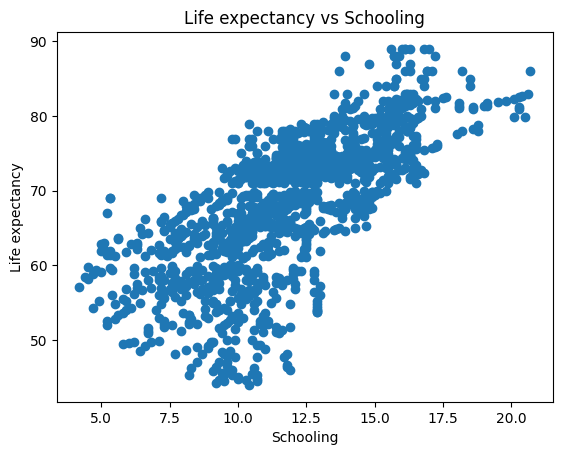

In [16]:
import matplotlib
plt.scatter(df["Schooling"], df["Life_expectancy"])
plt.xlabel("Schooling")
plt.ylabel("Life expectancy")
plt.title("Life expectancy vs Schooling")
plt.show()

## Checkpoint : 1 
Call your teacher to validate the parts 1 and 2

## STEP 3: Simple Linear Regression

In [17]:
import numpy as np

**TO CODE 3.1**

Select the Life Expectancy and the Income composition of resources of Belarus, Madagascar, India and Lithuania. This new Data Frame will be called df_study

In [21]:
df_study = df[(df.Country== "Belarus")|(df.Country== "Madagascar")|(df.Country== "India")|(df.Country== "Lithuania")]
df_study= df_study[["Country","Life_expectancy","Income_composition_of_resources"]]
print("df_study: ",df_study)

df_study:           Country  Life_expectancy  Income_composition_of_resources
225      Belarus             72.0                            0.796
226      Belarus             71.7                            0.796
227      Belarus             71.9                            0.793
228      Belarus             72.0                            0.787
229      Belarus             73.0                            0.780
230      Belarus             70.0                            0.771
231      Belarus             70.0                            0.755
232      Belarus             69.8                            0.739
233      Belarus             68.9                            0.723
234      Belarus             68.1                            0.713
235      Belarus             68.2                            0.703
236      Belarus             67.7                            0.695
237      Belarus             67.2                            0.687
238      Belarus             67.7                  

**TO CODE 3.2**

Implement a simple least square function and apply it on the previous selected data.

In [18]:
def leastSquare(x,y):
    x_mean = x.mean()
    y_mean = y.mean()

    beta1 = ((x-x_mean)*(y-y_mean)).sum()/((x-x_mean)**2).sum()
    beta0 = y_mean-beta1*x_mean
    return beta0, beta1

In [22]:
x = df_study["Income_composition_of_resources"].to_numpy()
y = df_study["Life_expectancy"].to_numpy()

beta0,beta1= leastSquare(x,y)
print("Beta0: ", beta0)
print("Beta1: ", beta1)

Beta0:  49.34763518833232
Beta1:  28.5982261406769


**TO CODE 3.3**

On the same figure, draw the line corresponding to your regression and the data points corresponding to df_study

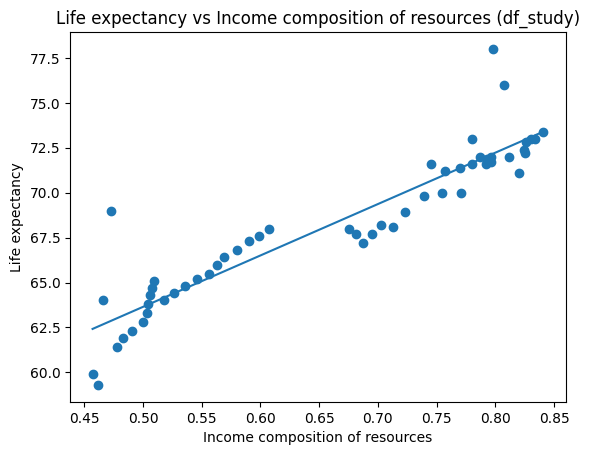

In [23]:
plt.scatter(x,y)
x_line = np.linspace(x.min(), x.max(), 100)
y_line= beta0+beta1*x_line
plt.xlabel("Income composition of resources")
plt.ylabel("Life expectancy")
plt.plot(x_line,y_line)
plt.title("Life expectancy vs Income composition of resources (df_study)")
plt.show()

## Checkpoint : 2
Call your teacher to validate the least square section

**TO CODE 3.4**

Now, implement a Gradient Descend function `def gradDescent(x, y, w, alpha, iters)` where `x` are
the covariates, `y` the target value, `w` the initial weights, `alpha` the learning rate and `iters` the number of gradient descent iterations. Your function should return all intermediary values of `w` that has been computed as a list.

As a gentle reminder, Gradient Descent is an optimization algorithm for finding a local minimum of a differentiable function. It is an iterative algorithm that aim to find the `w`  that minimizes our objective function. Since we aim to minimize the squared error, we aim to minimize the function : $L(y, \hat{y})=\sum\limits_{i=1}^n (y_i - w_1x_i-w_0)^2 $

Since previous function is convex, the derivative at each point indicate the **opposite** direction of the minimum. Thus, the idea is to update each weight by a small proportion of the opposite of this direction : 
$w_i^{t+1} = w_i^t - \alpha \frac{d(L(y, \hat{y}))}{d(w_i)}$

Be careful : here we have to update two weights, so we have to compute both derivative. Pay also attention on the fact that the derivative is computed according to $w_i$. Once you noticed that, calculating the derivative is pretty straightforward

In [24]:
def gradDescent(x,y,w,alpha,iters):
    beta0= w[0]
    beta1= w[1]
    history= [w]

    for i in range(iters):
        
        d_b0= (2*(y-beta0-beta1*x)*(-1)).sum()
        d_b1= (2*(y-beta0-beta1*x)*(-x)).sum()
        beta0 = beta0-alpha*d_b0
        beta1=beta1-alpha*d_b1

        history.append([beta0,beta1])
    return history

**TO CODE 3.5**

Compute the gradient descend on df_study for 1000 iterations with different values of `alpha`. You
may initialize `theta` with `theta_0 = 0` and `theta_1 = 1`

In [25]:
theta0=0
theta1=1

alpha_list=[0.0001,0.001,0.01]
for alpha in alpha_list:
    w_history = gradDescent(x,y,[theta0,theta1],alpha,1000)
    print("alpha: ",alpha,"final w: ",w_history[-1])

alpha:  0.0001 final w:  [np.float64(47.15404023772175), np.float64(31.87712771875031)]
alpha:  0.001 final w:  [np.float64(48.678551619995254), np.float64(29.598351299813547)]
alpha:  0.01 final w:  [np.float64(49.347630875381824), np.float64(28.598232587540185)]


**TO CODE 3.6**

On the same figure, plot the evolution of theta_0 through the iterations for each different values of
alpha you chose. Do the same thing for theta_1.

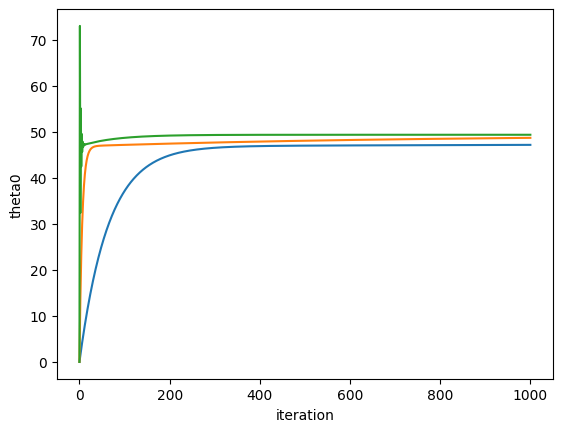

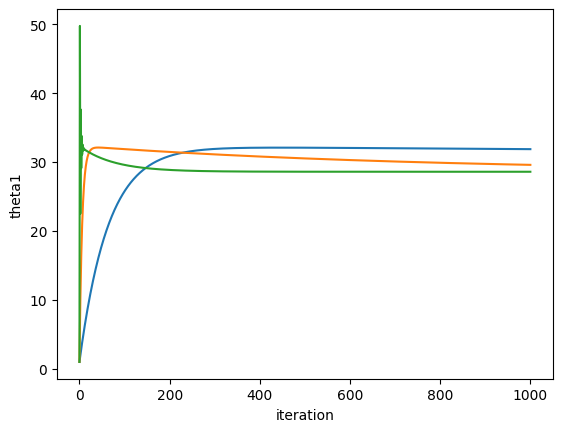

In [26]:
histories ={}
for alpha in alpha_list:
    histories[alpha]= gradDescent(x,y,[theta0,theta1],alpha,1000)
plt.figure()
for alpha in alpha_list:
    theta0Values=[w[0] for w in histories[alpha]]
    plt.plot(theta0Values)
plt.xlabel("iteration")
plt.ylabel("theta0")
plt.legend
plt.show()

plt.figure()
for alpha in alpha_list:
    theta1Values=[w[1] for w in histories[alpha]]
    plt.plot(theta1Values)
plt.xlabel("iteration")
plt.ylabel("theta1")
plt.legend
plt.show()

**Question 7**

Discuss on the role of alpha

we need alpha to be such that we dont overhsoot , yet reach the target within a reasonable speed and not slow (unlike blue) in this case the optimal curve is the orange ones

$R^2$ is the coefficient of determination useful to score a regression against the ground truth data.

This coefficient can be computed with a sklearn function:

```
sklearn.metrics.r2_score(y_true, y_pred, *, sample_weight=None, multioutput='uniform_average')
```

With:

**y_true** array-like of shape (n_samples,) or (n_samples, n_outputs)

Ground truth (correct) target values.

**y_pred** array-like of shape (n_samples,) or (n_samples, n_outputs)

Estimated target values.

**sample_weight** array-like of shape (n_samples,), default=None

Sample weights.

**multioutput** {‘raw_values’, ‘uniform_average’, ‘variance_weighted’}, array-like of shape (n_outputs,) or None, default=’uniform_average’

Defines aggregating of multiple output scores. Array-like value defines weights used to average scores. Default is “uniform_average”.

- ‘raw_values’: Returns a full set of scores in case of multioutput input.

- ‘uniform_average’: Scores of all outputs are averaged with uniform weight.

- ‘variance_weighted’: Scores of all outputs are averaged, weighted by the variances of each individual output.


In [27]:
from sklearn.metrics import r2_score

**TO CODE 3.7**

Compute $R^2$ on the regression with df_study

In [28]:
y_hat= beta0+beta1*x
R2=r2_score(y,y_hat)
print(R2)

0.846632270152281


**QUESTION 8**

Is linear regression suited between the two selected variables?

yes

**QUESTION 9**

If not, what would be the relevant regression between these two variables?

we'd need a parablic or logarithmic regression

## Checkpoint : 3
Call your teacher to validate the rest of section 3

## STEP 4: Diagnostic visualization

**TO CODE 4.1**

Compute the residuals and plot the residuals vs fitted values.

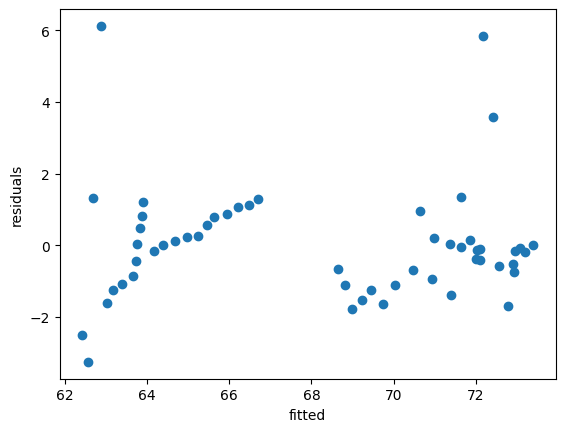

In [30]:
y_hat= beta0+beta1*x
residuals= y-y_hat

plt.scatter(y_hat,residuals)
plt.ylabel("residuals")
plt.xlabel("fitted")
plt.show()

**Question 10**

What can you conclude about this plot ?


gausian distribution 

**TO CODE 4.2**

Also compute the Scale Location plot


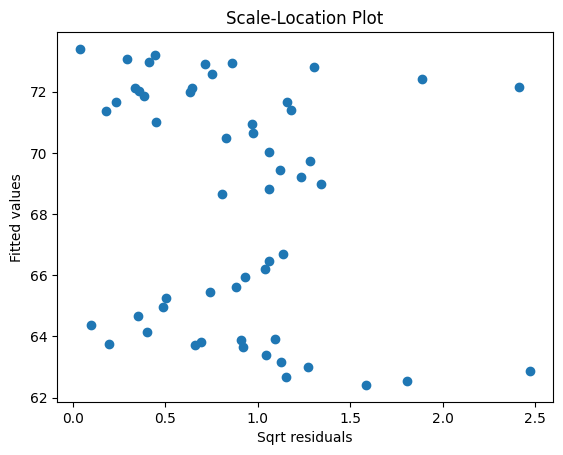

In [31]:
sqrt_abs_residuals = np.sqrt(np.abs(residuals))
plt.scatter(sqrt_abs_residuals, y_hat)

plt.ylabel("Fitted values")
plt.xlabel("Sqrt residuals")
plt.title("Scale-Location Plot")
plt.show()

**Question 11**

What can you conclude about this plot ?


**TO CODE 4.3**

Compute now the Cook's distance for our data. You can compute it by yourself or use any library you can find.


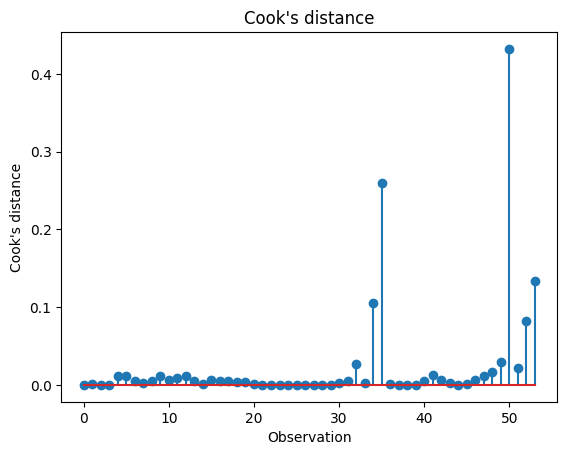

In [32]:
import statsmodels.api as sm
X = sm.add_constant(x)
model = sm.OLS(y, X).fit()
influence = model.get_influence()
cook = influence.cooks_distance[0]
plt.stem(cook)
plt.xlabel("Observation")
plt.ylabel("Cook's distance")
plt.title("Cook's distance")
plt.show()

**Question 12**

What can you conclude about this plot ?


the observations in which if we neglected how much of a difference it would make 

**TO DO 4.1** 

We are now adding multiple variable in our regression problem. Run the following cell in order to add multiple variables to your model : 

In [ ]:
from sklearn.preprocessing import scale
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import mean_squared_error

df_study = df[(df.Country == "Belarus") | (df.Country == "Madagascar") | (df.Country == "India") | (df.Country == "Lithuania")]
y = df_study.Life_expectancy
X = df_study[['Adult_mortality', 'Alcohol', 'Total_expenditure', 'Income_composition_of_resources', 'Schooling', "HIV_AIDS"]].to_numpy(dtype='float64')

**TO CODE 4.4**

Dealing with too many variables can sometimes be counter-productive and it can be more interesting to remove some features. One way to evaluate the importance of each variable is to compute the f_test whose function is named f_regression in sklearn. 

In [ ]:
from sklearn.feature_selection import f_regression
F, p = f_regression(X, y)
print("F values: ",F)
print("P values: ",p)

F values:  [  3.86444214 125.09281253  36.7294203  287.05437638 261.50896011
 106.622723  ]
P values:  [5.46696734e-02 1.89196805e-15 1.54511271e-07 8.04713883e-23
 6.21204994e-22 3.39511137e-14]


**QUESTION 13**

According to the f_test, rank each variable from the least to the most promising. Compare it with the correlation of your subset.

income composition of resources , has the highest F value, second was schooling. Matches somehow the the correclation subset since it was second most promising in correlation the first was shcooling. 

In [ ]:
print(df_study.corr(numeric_only=True)["Life_expectancy"])

Year                               0.125010
Life_expectancy                    1.000000
Adult_mortality                   -0.263012
Infant_deaths                     -0.318095
Alcohol                            0.840457
Percentage_expenditure             0.600736
Hepatitis_B                        0.568293
Measles                           -0.408752
BMI                                0.614425
Under-five_deaths                 -0.321385
Polio                              0.373330
Total_expenditure                  0.643388
Diphtheria                         0.529799
HIV_AIDS                          -0.819865
GDP                                0.617975
Population                        -0.247169
Thinness _1-19_years              -0.448016
Thinness_5-9_years                -0.439450
Income_composition_of_resources    0.920126
Schooling                          0.913310
Name: Life_expectancy, dtype: float64


## Checkpoint : 4
Call your teacher to validate the section 4. Congrats, you finished the first TP !